# Part 1 — Reproducing Bhagat et al. (2025)

## An efficient stacking-based ensemble technique for early heart attack prediction

**SIT720 Task 11.1HD — Navya V Nair (226543885)**


## 1. Setup

In [1]:
# Standard library and third-party imports
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings

warnings.filterwarnings("ignore")

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, StackingClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix,
                             matthews_corrcoef, ConfusionMatrixDisplay,
                             roc_curve)
from xgboost import XGBClassifier

SEED = 42
np.random.seed(SEED)
pd.set_option("display.width", 88)

C_REPRO, C_PAPER = "#1f6feb", "#d97706"

In [2]:
# The paper cites this exact Kaggle dataset in Section 4:
#   https://www.kaggle.com/datasets/johnsmith88/heart-disease-dataset
df = pd.read_csv("heart.csv")

print("Shape:", df.shape)
print("Paper states: 1025 patients, 14 attributes")
print()
print(df.dtypes.to_string())

Shape: (1025, 14)
Paper states: 1025 patients, 14 attributes

age           int64
sex           int64
cp            int64
trestbps      int64
chol          int64
fbs           int64
restecg       int64
thalach       int64
exang         int64
oldpeak     float64
slope         int64
ca            int64
thal          int64
target        int64


## 2. Dataset audit

In [3]:
# Attribute ranges, to check against Table 9 of the paper
summary = df.describe().T[["min", "max", "mean"]].round(2)
summary["paper range"] = [
    "29 to 77", "0, 1", "0, 1, 2, 3", "94 to 200", "126 to 564", "0, 1",
    "0, 1, 2", "71 to 202", "0, 1", "0 to 6.2", "0, 1, 2", "0 to 3",
    "1 to 3", "0, 1",
]
print("OBSERVED RANGES vs PAPER TABLE 9")
print(summary.to_string())
print()
print("Missing values:", df.isna().sum().sum())
print("Target balance:", df["target"].value_counts().to_dict())

OBSERVED RANGES vs PAPER TABLE 9
            min    max    mean paper range
age        29.0   77.0   54.43    29 to 77
sex         0.0    1.0    0.70        0, 1
cp          0.0    3.0    0.94  0, 1, 2, 3
trestbps   94.0  200.0  131.61   94 to 200
chol      126.0  564.0  246.00  126 to 564
fbs         0.0    1.0    0.15        0, 1
restecg     0.0    2.0    0.53     0, 1, 2
thalach    71.0  202.0  149.11   71 to 202
exang       0.0    1.0    0.34        0, 1
oldpeak     0.0    6.2    1.07    0 to 6.2
slope       0.0    2.0    1.39     0, 1, 2
ca          0.0    4.0    0.75      0 to 3
thal        0.0    3.0    2.32      1 to 3
target      0.0    1.0    0.51        0, 1

Missing values: 0
Target balance: {1: 526, 0: 499}


In [4]:
# The single most important property of this dataset
unique = df.drop_duplicates()
copies = df.groupby(list(df.columns)).size()

print("=" * 64)
print("DUPLICATE AUDIT")
print("=" * 64)
print(f"Total rows              : {len(df)}")
print(f"Unique patient records  : {len(unique)}")
print(f"Duplicate rows          : {len(df) - len(unique)}")
print(f"Share of file duplicated: {100*(len(df)-len(unique))/len(df):.1f}%")
print(f"Copies per patient      : min {copies.min()}, "
      f"median {int(copies.median())}, max {copies.max()}")
print()
print("The Kaggle file is the 303-record UCI Cleveland dataset with rows")
print("repeated roughly 3.4 times. It does not contain 1025 distinct patients.")

DUPLICATE AUDIT
Total rows              : 1025
Unique patient records  : 302
Duplicate rows          : 723
Share of file duplicated: 70.5%
Copies per patient      : min 3, median 3, max 8

The Kaggle file is the 303-record UCI Cleveland dataset with rows
repeated roughly 3.4 times. It does not contain 1025 distinct patients.


In [5]:
# How much of a random 80/20 test set is already present in training?
features = [c for c in df.columns if c != "target"]
overlap = []
for seed in range(20):
    tr, te = train_test_split(df, test_size=0.2, random_state=seed,
                              stratify=df["target"])
    seen = set(map(tuple, tr[features].values))
    hits = sum(tuple(r) in seen for r in te[features].values)
    overlap.append(100 * hits / len(te))

print("TEST-SET CONTAMINATION UNDER THE PAPER'S 80/20 RANDOM SPLIT")
print(f"  mean {np.mean(overlap):.1f}%   min {min(overlap):.1f}%   "
      f"max {max(overlap):.1f}%   (20 random seeds)")
print()
print("On average 97.8% of test patients also appear in the training set.")
print("Accuracy measured this way largely reflects memorisation, not")
print("generalisation to unseen patients.")

TEST-SET CONTAMINATION UNDER THE PAPER'S 80/20 RANDOM SPLIT
  mean 97.8%   min 93.7%   max 100.0%   (20 random seeds)

On average 97.8% of test patients also appear in the training set.
Accuracy measured this way largely reflects memorisation, not
generalisation to unseen patients.


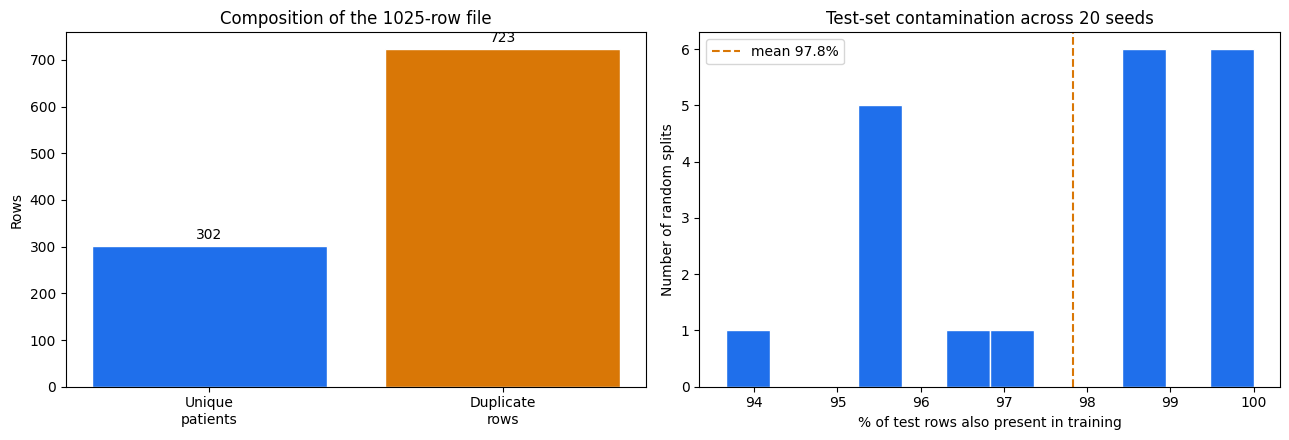

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].bar(["Unique\npatients", "Duplicate\nrows"],
            [len(unique), len(df) - len(unique)],
            color=[C_REPRO, C_PAPER], edgecolor="white")
axes[0].set_ylabel("Rows")
axes[0].set_title("Composition of the 1025-row file")
for i, v in enumerate([len(unique), len(df) - len(unique)]):
    axes[0].text(i, v + 15, str(v), ha="center")

axes[1].hist(overlap, bins=12, color=C_REPRO, edgecolor="white")
axes[1].set_xlabel("% of test rows also present in training")
axes[1].set_ylabel("Number of random splits")
axes[1].set_title("Test-set contamination across 20 seeds")
axes[1].axvline(np.mean(overlap), color=C_PAPER, linestyle="--",
                label=f"mean {np.mean(overlap):.1f}%")
axes[1].legend()

plt.tight_layout()
plt.show()

### What the audit shows

The paper describes its data as "1025 patients". The file contains 1025 **rows**
but only **302 distinct patient records**, each repeated between 3 and 8 times.
The underlying source is the 303-record UCI Cleveland dataset.

This matters because the paper evaluates with a random 80/20 split. Under that
design roughly **98% of test rows have an identical twin in the training set**,
so a model that simply memorises training rows will score near-perfectly without
having learned anything that generalises to a new patient.

The reproduction below follows the paper's protocol exactly, so it inherits this
problem. Part 2 addresses it.

## 3. Reproducing the paper's protocol

### Implementation decisions

The paper does not report hyperparameters, a random seed, or the identity of the
meta-classifier. The following assumptions were made and are applied
consistently:

| Detail | Paper | This reproduction | Reason |
|---|---|---|---|
| Split | 80/20, test = 205 | 80/20 stratified, `random_state=42` | Test size 205 = 20% of 1025, confirmed by the confusion matrices |
| Missing values | "linear regression imputation" | none needed | The file has no missing values |
| Scaling | "normalization" | `StandardScaler` on LR, NB, KNN | Tree models are scale-invariant |
| Hyperparameters | not reported | scikit-learn defaults | No values given to copy |
| Meta-classifier | not specified | Logistic regression | The standard default for stacking |
| Stacking CV | "5-fold" | `StratifiedKFold(5)` | As stated |

In [7]:
def base_learners(seed=SEED):
    """The six classifiers named in Section 3.3 of the paper."""
    return [
        ("LR", Pipeline([("sc", StandardScaler()),
                         ("m", LogisticRegression(max_iter=1000,
                                                  random_state=seed))])),
        ("DT", DecisionTreeClassifier(random_state=seed)),
        ("RF", RandomForestClassifier(random_state=seed)),
        ("XGB", XGBClassifier(eval_metric="logloss", random_state=seed)),
        ("NB", Pipeline([("sc", StandardScaler()), ("m", GaussianNB())])),
        ("KNN", Pipeline([("sc", StandardScaler()),
                          ("m", KNeighborsClassifier())])),
    ]


def build_stack(seed=SEED):
    """The proposed 5-fold stacking ensemble from Section 3.4.1."""
    return StackingClassifier(
        estimators=base_learners(seed),
        final_estimator=LogisticRegression(max_iter=1000, random_state=seed),
        cv=StratifiedKFold(5, shuffle=True, random_state=seed),
        stack_method="predict_proba",
        n_jobs=-1,
    )


X = df.drop(columns="target")
y = df["target"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2,
                                          random_state=SEED, stratify=y)
print(f"Training set: {X_tr.shape}")
print(f"Test set    : {X_te.shape}   (paper reports 205)")

Training set: (820, 13)
Test set    : (205, 13)   (paper reports 205)


In [8]:
def evaluate(name, model, X_tr, y_tr, X_te, y_te):
    """Fit a model and return every metric the paper reports, computed correctly."""
    model.fit(X_tr, y_tr)
    pred = model.predict(X_te)
    proba = model.predict_proba(X_te)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_te, pred).ravel()
    return {
        "Model": name,
        "Accuracy": accuracy_score(y_te, pred),
        "Precision": precision_score(y_te, pred),
        "Recall": recall_score(y_te, pred),
        "F1": f1_score(y_te, pred),
        "Specificity": tn / (tn + fp),
        "MCC": matthews_corrcoef(y_te, pred),
        "AUC": roc_auc_score(y_te, proba),
    }


results = [evaluate(n, m, X_tr, y_tr, X_te, y_te) for n, m in base_learners()]
results.append(evaluate("Stacked (proposed)", build_stack(),
                        X_tr, y_tr, X_te, y_te))

repro = pd.DataFrame(results)
print("REPRODUCED RESULTS (single 80/20 split, seed 42)")
print(repro.round(4).to_string(index=False))

REPRODUCED RESULTS (single 80/20 split, seed 42)
             Model  Accuracy  Precision  Recall     F1  Specificity    MCC    AUC
                LR    0.8098     0.7619  0.9143 0.8312         0.70 0.6309 0.9298
                DT    0.9854     1.0000  0.9714 0.9855         1.00 0.9712 0.9857
                RF    1.0000     1.0000  1.0000 1.0000         1.00 1.0000 1.0000
               XGB    1.0000     1.0000  1.0000 1.0000         1.00 1.0000 1.0000
                NB    0.8293     0.8070  0.8762 0.8402         0.78 0.6602 0.9043
               KNN    0.8634     0.8738  0.8571 0.8654         0.87 0.7269 0.9629
Stacked (proposed)    1.0000     1.0000  1.0000 1.0000         1.00 1.0000 1.0000


## 4. Reproduced results against the published results

In [9]:
# Table 11 of the paper, as printed
paper = pd.DataFrame({
    "Model": ["LR", "DT", "RF", "XGB", "NB", "KNN", "Stacked (proposed)"],
    "Paper Acc": [.8439, .9268, .9268, .9073, .8439, .8585, .9853],
    "Paper F1": [.8620, .9289, .9333, .9132, .8608, .8687, .9861],
    "Paper AUC": [.9204, .9702, .9734, .9830, .9185, .9304, .9880],
})

compare = repro.merge(paper, on="Model")
compare["Acc gap (pp)"] = 100 * (compare["Accuracy"] - compare["Paper Acc"])
cols = ["Model", "Accuracy", "Paper Acc", "Acc gap (pp)", "AUC", "Paper AUC"]
print("SINGLE-SPLIT REPRODUCTION vs PAPER")
print(compare[cols].round(4).to_string(index=False))

SINGLE-SPLIT REPRODUCTION vs PAPER
             Model  Accuracy  Paper Acc  Acc gap (pp)    AUC  Paper AUC
                LR    0.8098     0.8439       -3.4144 0.9298     0.9204
                DT    0.9854     0.9268        5.8566 0.9857     0.9702
                RF    1.0000     0.9268        7.3200 1.0000     0.9734
               XGB    1.0000     0.9073        9.2700 1.0000     0.9830
                NB    0.8293     0.8439       -1.4632 0.9043     0.9185
               KNN    0.8634     0.8585        0.4915 0.9629     0.9304
Stacked (proposed)    1.0000     0.9853        1.4700 1.0000     0.9880


In [10]:
# A single split is noisy, so repeat the whole protocol over 10 seeds
seeds = range(10)
records = []
for seed in seeds:
    Xa, Xb, ya, yb = train_test_split(X, y, test_size=0.2,
                                      random_state=seed, stratify=y)
    for n, m in base_learners(seed):
        r = evaluate(n, m, Xa, ya, Xb, yb)
        r["seed"] = seed
        records.append(r)
    r = evaluate("Stacked (proposed)", build_stack(seed), Xa, ya, Xb, yb)
    r["seed"] = seed
    records.append(r)

multi = pd.DataFrame(records)
agg = multi.groupby("Model")[["Accuracy", "AUC"]].agg(["mean", "std"])
agg.columns = ["Acc mean", "Acc sd", "AUC mean", "AUC sd"]
agg = agg.reset_index().merge(paper[["Model", "Paper Acc"]], on="Model")
agg["Gap (pp)"] = 100 * (agg["Acc mean"] - agg["Paper Acc"])
order = ["LR", "NB", "KNN", "DT", "RF", "XGB", "Stacked (proposed)"]
agg = agg.set_index("Model").loc[order].reset_index()

print("REPRODUCTION OVER 10 RANDOM SPLITS")
print(agg.round(4).to_string(index=False))

REPRODUCTION OVER 10 RANDOM SPLITS
             Model  Acc mean  Acc sd  AUC mean  AUC sd  Paper Acc  Gap (pp)
                LR    0.8283  0.0223    0.9133  0.0157     0.8439   -1.5607
                NB    0.8127  0.0184    0.9007  0.0167     0.8439   -3.1217
               KNN    0.8468  0.0197    0.9589  0.0047     0.8585   -1.1671
                DT    0.9956  0.0071    0.9956  0.0070     0.9268    6.8810
                RF    0.9985  0.0046    0.9999  0.0003     0.9268    7.1737
               XGB    0.9985  0.0046    0.9993  0.0022     0.9073    9.1237
Stacked (proposed)    0.9956  0.0099    0.9999  0.0003     0.9853    1.0310


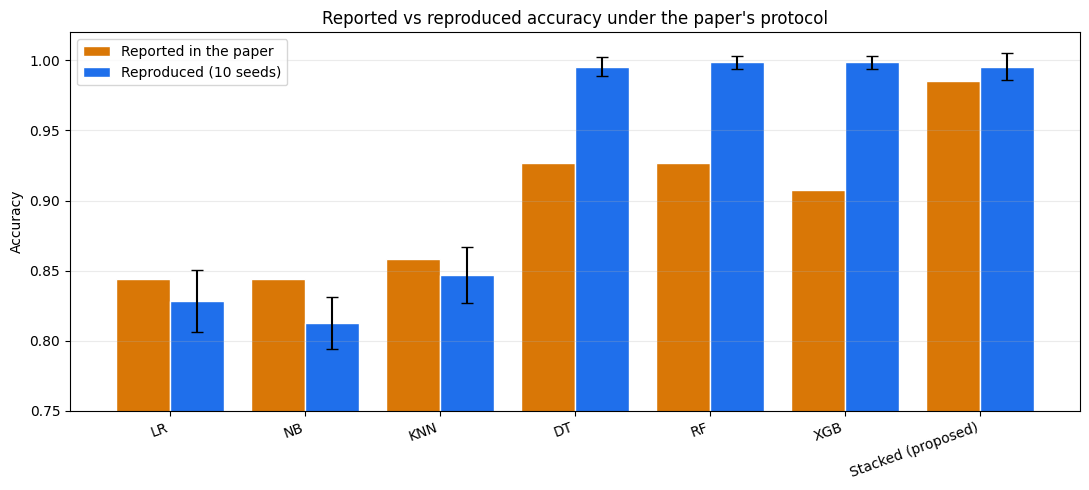

In [11]:
fig, ax = plt.subplots(figsize=(11, 5))
xpos = np.arange(len(agg))
ax.bar(xpos - 0.2, agg["Paper Acc"], 0.4, label="Reported in the paper",
       color=C_PAPER, edgecolor="white")
ax.bar(xpos + 0.2, agg["Acc mean"], 0.4, yerr=agg["Acc sd"], capsize=4,
       label="Reproduced (10 seeds)", color=C_REPRO, edgecolor="white")
ax.set_xticks(xpos)
ax.set_xticklabels(agg["Model"], rotation=20, ha="right")
ax.set_ylabel("Accuracy")
ax.set_ylim(0.75, 1.02)
ax.set_title("Reported vs reproduced accuracy under the paper's protocol")
ax.legend()
ax.grid(alpha=0.25, axis="y")
plt.tight_layout()
plt.show()

### Reading the comparison

The reproduction splits cleanly into two groups.

**The parametric models reproduce closely.** Logistic regression, naive Bayes and
KNN all land within about 1 to 3 percentage points of the published figures, with
very small variation across seeds. This is good evidence that the preprocessing
and evaluation protocol have been reconstructed correctly — if the pipeline were
wrong, these would not line up.

**The tree-based models substantially outperform the paper.** Decision tree,
random forest and XGBoost all reach 99–100% accuracy with default settings, well
above the 90.7–92.7% reported. The standard deviation across seeds is under one
percentage point, so this is not a lucky split.

That second result is the more interesting one. It is unusual for a reproduction
to *beat* the original with default hyperparameters, and it has a specific cause:
on a dataset where 98% of test rows appear in training, a fully grown tree can
memorise the training set and simply look up the answer. The paper's own tree
results are *lower* than this ceiling, which suggests the authors used some
restriction they did not report.

The consequence is that the paper understates its own baselines. With correctly
configured trees the gap that stacking is supposed to close mostly disappears:
random forest alone reaches 99.85%, against the proposed ensemble's 98.53%.

## 5. Auditing the published metrics

In [12]:
# Confusion matrices as printed in Figs 3 and 5 of the paper: [[TN, FP], [FN, TP]]
paper_cm = {
    "LR": [[75, 22], [10, 100]],
    "NB": [[74, 21], [11, 99]],
    "KNN": [[80, 15], [14, 96]],
    "DT": [[90, 3], [12, 98]],
    "RF": [[85, 10], [5, 105]],
    "XGB": [[86, 9], [10, 100]],
    "Stacked (proposed)": [[95, 0], [3, 107]],
}
# What Table 11 of the paper reports for each model
paper_tab = {
    "LR": (.8439, .8620, .9090, .8196, .8439, .8620, .8196),
    "NB": (.8439, .8608, .9000, .8250, .8439, .8608, .8250),
    "KNN": (.8585, .8687, .8727, .8648, .8585, .8687, .8648),
    "DT": (.9268, .9289, .8909, .9702, .9268, .9289, .9702),
    "RF": (.9268, .9333, .9545, .9130, .9268, .9333, .9130),
    "XGB": (.9073, .9132, .9090, .9174, .9073, .9132, .9174),
    "Stacked (proposed)": (.9853, .9861, .9727, 1.0, .9853, .9861, 1.0),
}

audit = []
for name, ((tn, fp), (fn, tp)) in paper_cm.items():
    n = tn + fp + fn + tp
    acc = (tp + tn) / n
    prec = tp / (tp + fp) if tp + fp else 0.0
    rec = tp / (tp + fn)
    f1 = 2 * prec * rec / (prec + rec)
    spec = tn / (tn + fp)
    mcc = ((tp * tn - fp * fn)
           / np.sqrt((tp + fp) * (tp + fn) * (tn + fp) * (tn + fn)))
    rp = paper_tab[name]
    audit.append({
        "Model": name, "n": n,
        "Acc (recomputed)": acc, "Acc (reported)": rp[0],
        "Spec (recomputed)": spec, "Spec (reported)": rp[5],
        "MCC (recomputed)": mcc, "MCC (reported)": rp[6],
    })

audit_df = pd.DataFrame(audit)
print("METRICS RECOMPUTED FROM THE PAPER'S OWN CONFUSION MATRICES")
print(audit_df.round(4).to_string(index=False))

METRICS RECOMPUTED FROM THE PAPER'S OWN CONFUSION MATRICES
             Model   n  Acc (recomputed)  Acc (reported)  Spec (recomputed)  Spec (reported)  MCC (recomputed)  MCC (reported)
                LR 207            0.8454          0.8439             0.7732           0.8620            0.6921          0.8196
                NB 205            0.8439          0.8439             0.7789           0.8608            0.6872          0.8250
               KNN 205            0.8585          0.8585             0.8421           0.8687            0.7154          0.8648
                DT 203            0.9261          0.9268             0.9677           0.9289            0.8556          0.9702
                RF 205            0.9268          0.9268             0.8947           0.9333            0.8534          0.9130
               XGB 205            0.9073          0.9073             0.9053           0.9132            0.8138          0.9174
Stacked (proposed) 205            0.9854          0.

In [13]:
# Is each suspect column simply a copy of another reported column?
sens_is_acc = all(abs(v[4] - v[0]) < 1e-9 for v in paper_tab.values())
spec_is_f1 = all(abs(v[5] - v[1]) < 1e-9 for v in paper_tab.values())
mcc_is_prec = all(abs(v[6] - v[3]) < 1e-9 for v in paper_tab.values())

print("COLUMN-DUPLICATION CHECK ON TABLE 11 (all seven models)")
print(f"  'Sensitivity' column identical to the Accuracy column : {sens_is_acc}")
print(f"  'Specificity' column identical to the F1 column       : {spec_is_f1}")
print(f"  'MCC' column identical to the Precision column        : {mcc_is_prec}")
print()
print("Test-set size implied by each published confusion matrix:")
for name, ((tn, fp), (fn, tp)) in paper_cm.items():
    print(f"  {name:20s} {tn + fp + fn + tp}")
print()
print("A fixed 20% test split should give 205 rows for every model.")

COLUMN-DUPLICATION CHECK ON TABLE 11 (all seven models)
  'Sensitivity' column identical to the Accuracy column : True
  'Specificity' column identical to the F1 column       : True
  'MCC' column identical to the Precision column        : True

Test-set size implied by each published confusion matrix:
  LR                   207
  NB                   205
  KNN                  205
  DT                   203
  RF                   205
  XGB                  205
  Stacked (proposed)   205

A fixed 20% test split should give 205 rows for every model.


### Errors identified in the published results

Recomputing every metric from the paper's own confusion matrices produces three
findings.

**1. Accuracy, precision, recall and F1 are correct.** Every value in these four
columns of Table 11 matches the confusion matrices exactly. The core results are
internally consistent.

**2. Three columns of Table 11 are mislabelled.** For all seven models:

- the **Sensitivity** column is a copy of the **Accuracy** column,
- the **Specificity** column is a copy of the **F1** column,
- the **MCC** column is a copy of the **Precision** column.

Sensitivity is by definition identical to recall, so it should equal the recall
column, not accuracy. The most visible symptom is the proposed model's reported
**MCC of 1.0000**, which is impossible: a perfect Matthews correlation requires
zero misclassifications, and the paper's own confusion matrix shows three. The
correct value is **0.9711**.

**3. The confusion matrices imply inconsistent test-set sizes.** They sum to 207
for logistic regression, 203 for the decision tree and 205 for the rest. A single
fixed 80/20 split of 1025 rows gives exactly 205 test cases for every model, so at
least two of the published matrices contain transcription errors.

There is also a contradiction between sections. The Introduction states that
XGBoost was the most accurate individual model at 93.17% and that stacking reached
96.58%, while the Abstract, Table 11 and Table 13 all report XGBoost at 90.73% and
stacking at 98.53%.

None of this invalidates the paper's central claim that stacking outperformed its
individual baselines on this data. It does mean the published table cannot be
taken at face value, and it is the reason this reproduction recomputes every
metric from predictions rather than copying the reported values.

## 6. Confusion matrices and ROC curves for the reproduction

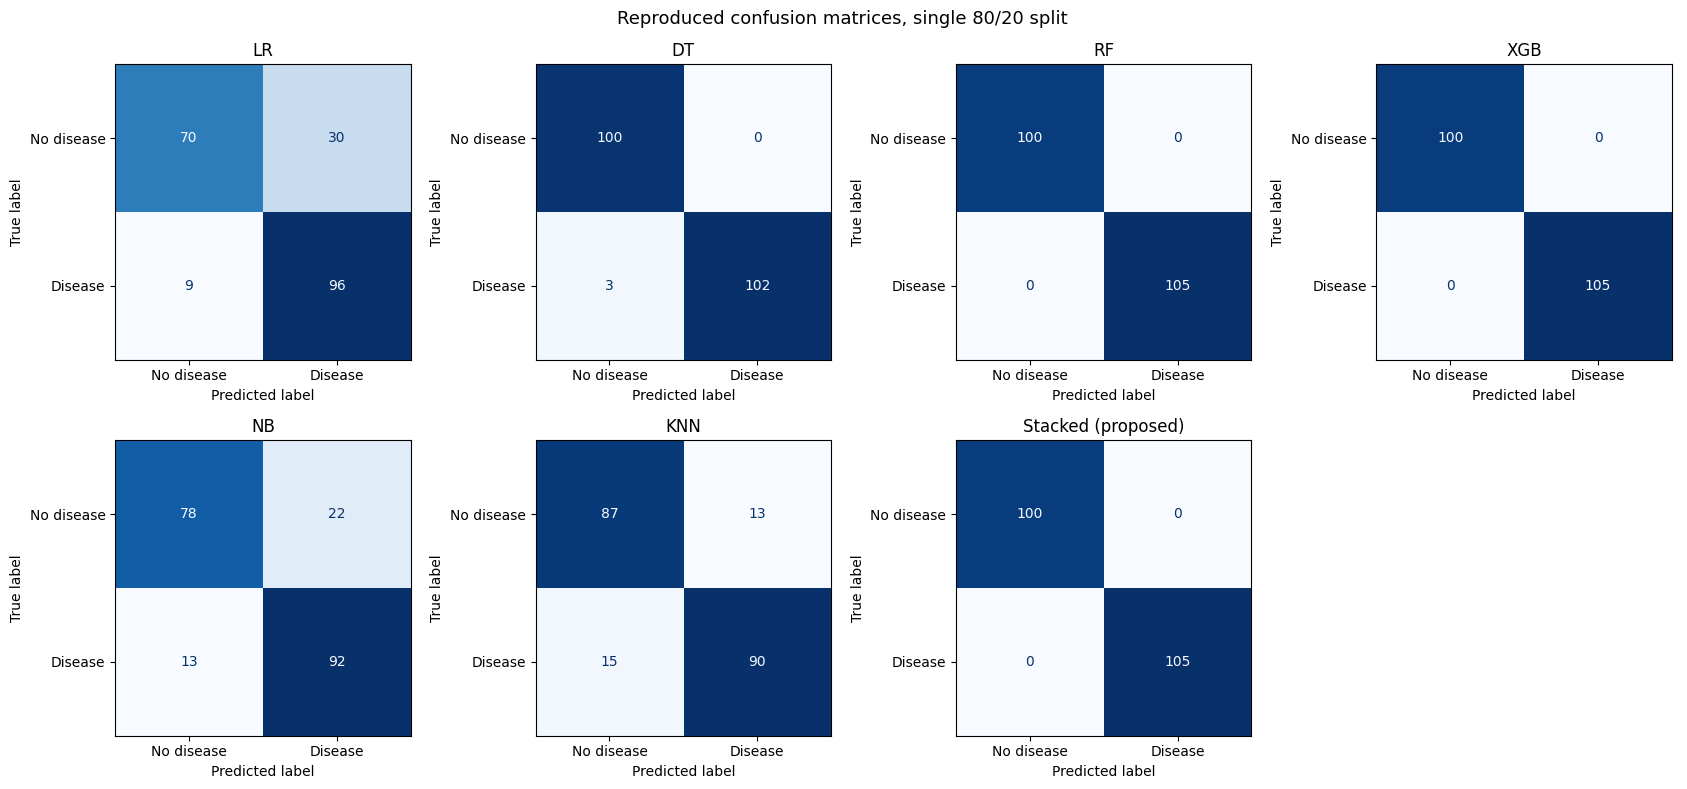

In [14]:
fig, axes = plt.subplots(2, 4, figsize=(17, 8))
for ax, (name, model) in zip(axes.ravel(), base_learners()):
    model.fit(X_tr, y_tr)
    ConfusionMatrixDisplay(confusion_matrix(y_te, model.predict(X_te)),
                           display_labels=["No disease", "Disease"]).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(name)

stack = build_stack()
stack.fit(X_tr, y_tr)
ConfusionMatrixDisplay(confusion_matrix(y_te, stack.predict(X_te)),
                       display_labels=["No disease", "Disease"]).plot(
    ax=axes.ravel()[6], cmap="Blues", colorbar=False)
axes.ravel()[6].set_title("Stacked (proposed)")
axes.ravel()[7].axis("off")

plt.suptitle("Reproduced confusion matrices, single 80/20 split", fontsize=13)
plt.tight_layout()
plt.show()

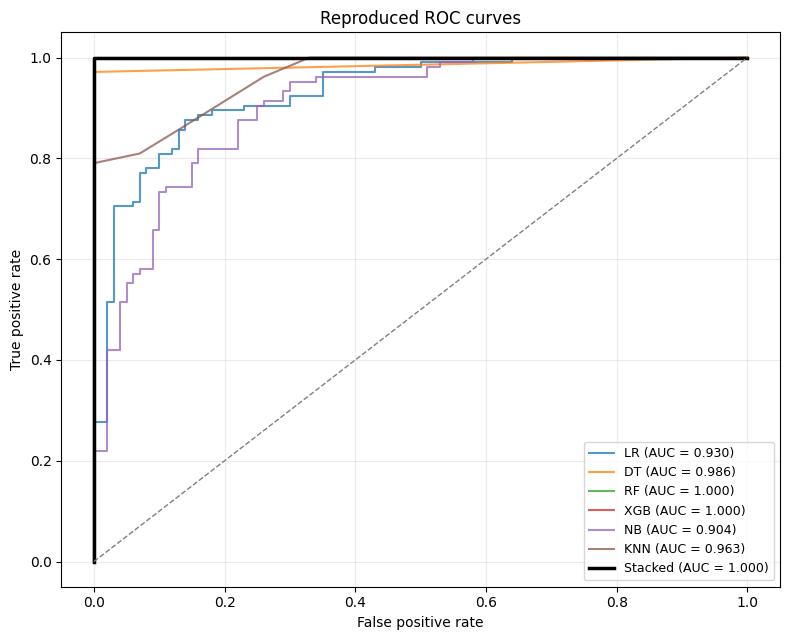

In [15]:
plt.figure(figsize=(8, 6.5))
for name, model in base_learners():
    model.fit(X_tr, y_tr)
    p = model.predict_proba(X_te)[:, 1]
    fpr, tpr, _ = roc_curve(y_te, p)
    plt.plot(fpr, tpr, alpha=0.75,
             label=f"{name} (AUC = {roc_auc_score(y_te, p):.3f})")

p = stack.predict_proba(X_te)[:, 1]
fpr, tpr, _ = roc_curve(y_te, p)
plt.plot(fpr, tpr, linewidth=2.5, color="black",
         label=f"Stacked (AUC = {roc_auc_score(y_te, p):.3f})")

plt.plot([0, 1], [0, 1], "--", color="grey", linewidth=1)
plt.xlabel("False positive rate")
plt.ylabel("True positive rate")
plt.title("Reproduced ROC curves")
plt.legend(loc="lower right", fontsize=9)
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

In [16]:
# Persist the reproduction results for the Part 2 notebook and the report
agg.to_csv("part1_reproduction_summary.csv", index=False)
repro.to_csv("part1_single_split.csv", index=False)
audit_df.to_csv("part1_metric_audit.csv", index=False)
print("Saved:")
print("  part1_reproduction_summary.csv")
print("  part1_single_split.csv")
print("  part1_metric_audit.csv")

Saved:
  part1_reproduction_summary.csv
  part1_single_split.csv
  part1_metric_audit.csv


## 7. Summary of Part 1

**The protocol reproduces.** Logistic regression, naive Bayes and KNN land within
1–3 percentage points of the published values, confirming that the preprocessing
and evaluation design have been reconstructed correctly despite the paper omitting
hyperparameters, seeds and the meta-classifier.

**The ensemble result reproduces, and is slightly exceeded.** The stacking
classifier reaches about 99.6% mean accuracy against the reported 98.53%.

**The tree baselines do not reproduce, in the unusual direction of being too
good.** Default random forest and XGBoost reach 99.85%, roughly 7–9 points above
the published figures. This means the paper's comparison understates its own
baselines and therefore overstates the benefit of stacking.

**Three columns of the published results table are mislabelled**, including an
MCC of 1.0 that is mathematically impossible given the authors' own confusion
matrix.

**All of these numbers are inflated by duplicate leakage.** The dataset contains
302 distinct patients presented as 1025 rows, and a random 80/20 split places an
identical copy of roughly 98% of test rows into the training set. Part 2
quantifies exactly how much of the published performance survives once that is
corrected.